## APP AND GITHUB

- GitHub repository: <add link to the part3 branch>
- Streamlit app: <add link>
- Screencast: <add Panopto link>

## Imports

In [1]:
# Check that every package for Part 3 imports
import geopandas as gpd
import shapely
import pyproj
import scipy
import sklearn
import statsmodels
import openmeteo_requests
import requests_cache
import pandas as pd

print("geopandas  ", gpd.__version__)
print("shapely    ", shapely.__version__)
print("scipy      ", scipy.__version__)
print("sklearn    ", sklearn.__version__)
print("statsmodels", statsmodels.__version__)

geopandas   1.2.0
shapely     2.2.0
scipy       1.18.1
sklearn     1.9.0
statsmodels 0.15.0


## Shapefiles

In [2]:
from pathlib import Path
import geopandas as gpd

# Shapefiles downloaded from atlas.nve.no
SHAPE_DIR = Path("../data/shapefiles")

# Electricity price areas (NVE calls them "budområder" - bidding zones)
elspot = gpd.read_file(SHAPE_DIR / "elspot" / "Budområder.shp")

# Regions matching the Magasinstatistikk data
regions = gpd.read_file(SHAPE_DIR / "NVE_Region" / "NVE_Region.shp")

print("Elspot  CRS:", elspot.crs)
print("Elspot  columns:", elspot.columns.tolist())
print()
print("Regions CRS:", regions.crs)
print("Regions columns:", regions.columns.tolist())

Elspot  CRS: EPSG:25833
Elspot  columns: ['objectid', 'budomr', 'globalid', 'st_area(sh', 'st_perimet', 'geometry']

Regions CRS: EPSG:25833
Regions columns: ['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED', 'BESÃ\x98KSADR', 'ADRESSE', 'geometry']


In [3]:
# Attribute table without the geometry column, which is unreadable as text
elspot.drop(columns="geometry")

,objectid,budomr,globalid,st_area(sh,st_perimet
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06


In [4]:
regions.drop(columns="geometry")

,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESÃKSADR,ADRESSE
0,1.0,RV,Region Vest,6801,FÃ¸rde,Naustdalsveien 1B,Postboks 53
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54
3,4.0,RÃ,Region Ãst,2307,Hamar,Vangsvegen 73,Postboks 4223
4,5.0,RS,Region SÃ¸r,3103,TÃ¸nsberg,Anton Jenssens gate 7,Postboks 2124


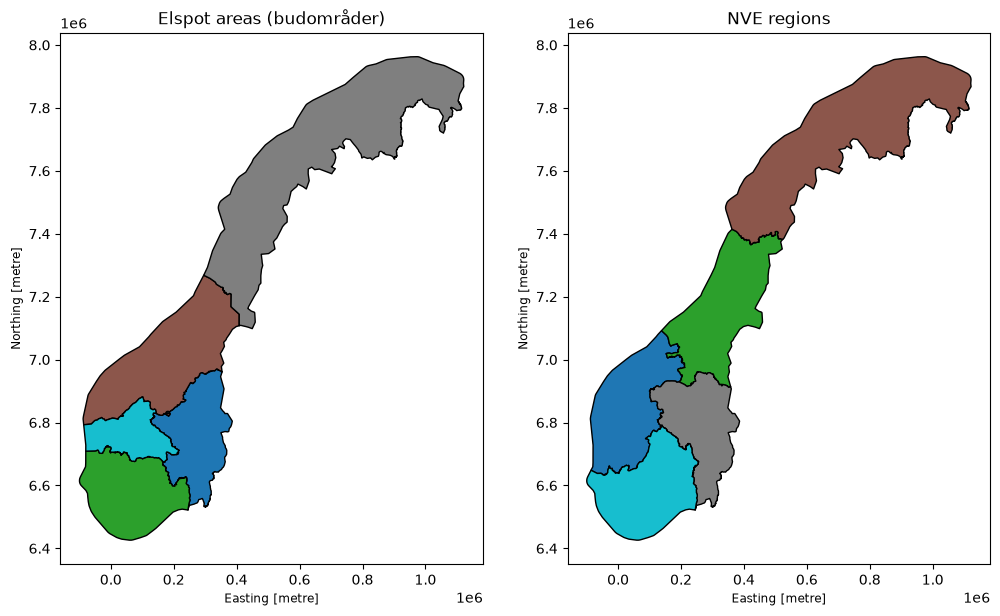

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
elspot.plot(ax=axes[0], edgecolor="black", cmap="tab10")
axes[0].set_title("Elspot areas (budområder)")
regions.plot(ax=axes[1], edgecolor="black", cmap="tab10")
axes[1].set_title("NVE regions")
plt.show()

## Turning the five regions into three

Since we usually work with VASS1-3 we combine the sør + øst to east and the midt + nord to north. 

In [6]:
# --- Watercourse areas (VASS): combine NVE's five regions into three ---
# The Magasinstatistikk data has VASS 1-3, while NVE has five regions.
# East = Sør + Øst, North = Midt + Nord, West stays as it is.
REGION_TO_VASS = {
    "RS": "VASS1", "RØ": "VASS1",   # East  (Sørøst-Norge)
    "RV": "VASS2",                  # West  (Vest-Norge)
    "RM": "VASS3", "RN": "VASS3",   # North (Midt- and Nord-Norge)
}

regions["region_id"] = regions["REGION"].map(REGION_TO_VASS)

# dissolve() merges all polygons that share a region_id into one shape
vass = regions.dissolve(by="region_id").reset_index()[["region_id", "geometry"]]
vass["area_type"] = "VASS"

# --- Electricity price areas (EL): "NO 1" -> "NO1" ---
el = elspot[["budomr", "geometry"]].copy()
el["region_id"] = el["budomr"].str.replace(" ", "", regex=False)
el["area_type"] = "EL"
el = el[["region_id", "area_type", "geometry"]]

# --- Norway total (NO): the union of the five price areas ---
no = gpd.GeoDataFrame(
    {"region_id": ["NO"], "area_type": ["NO"]},
    geometry=[el.union_all()],
    crs=el.crs,
)

# One table covering every area type the Magasinstatistikk uses
all_regions = gpd.GeoDataFrame(
    pd.concat([el, vass, no], ignore_index=True), crs=el.crs
)
all_regions[["region_id", "area_type"]]

,region_id,area_type
0,NO1,EL
1,NO2,EL
2,NO3,EL
3,NO4,EL
4,NO5,EL
5,VASS1,VASS
6,VASS2,VASS
7,VASS3,VASS
8,NO,NO


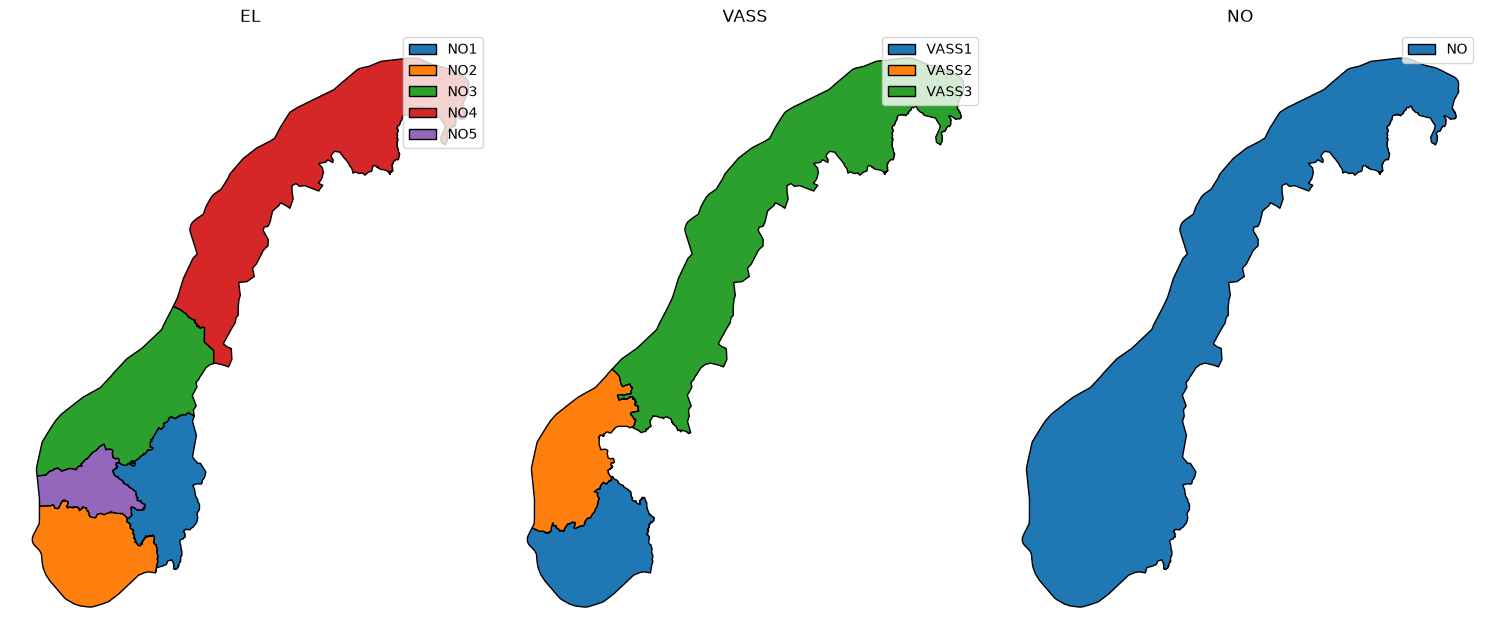

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, kind in zip(axes, ["EL", "VASS", "NO"]):
    sub = all_regions[all_regions["area_type"] == kind]
    sub.plot(ax=ax, column="region_id", edgecolor="black", legend=True, cmap="tab10")
    ax.set_title(kind)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Random sampling of locations

In [8]:
N_POINTS = 1000   # points per region, as the task asks
SEED = 42         # fixed seed, so the same points come out every run

# Sample while still in UTM 33 (metres), so the points are spread evenly
# by area. sample_points returns one MultiPoint per region.
samples = all_regions.copy()
samples["geometry"] = all_regions.sample_points(size=N_POINTS, rng=SEED)

# explode() turns each MultiPoint into 1000 separate rows
points = samples.explode(index_parts=False).reset_index(drop=True)

# Convert to longitude/latitude (WGS84), which open-meteo expects
points = points.to_crs(4326)
points["lon"] = points.geometry.x.round(4)
points["lat"] = points.geometry.y.round(4)

print(points.groupby("region_id").size())
points[["region_id", "area_type", "lon", "lat"]].head()

region_id
NO       1000
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
VASS1    1000
VASS2    1000
VASS3    1000
dtype: int64


,region_id,area_type,lon,lat
0,NO1,EL,9.5723,60.7744
1,NO1,EL,11.3065,61.4410
2,NO1,EL,8.1826,61.2529
3,NO1,EL,11.5315,62.0135
4,NO1,EL,10.6569,61.3560


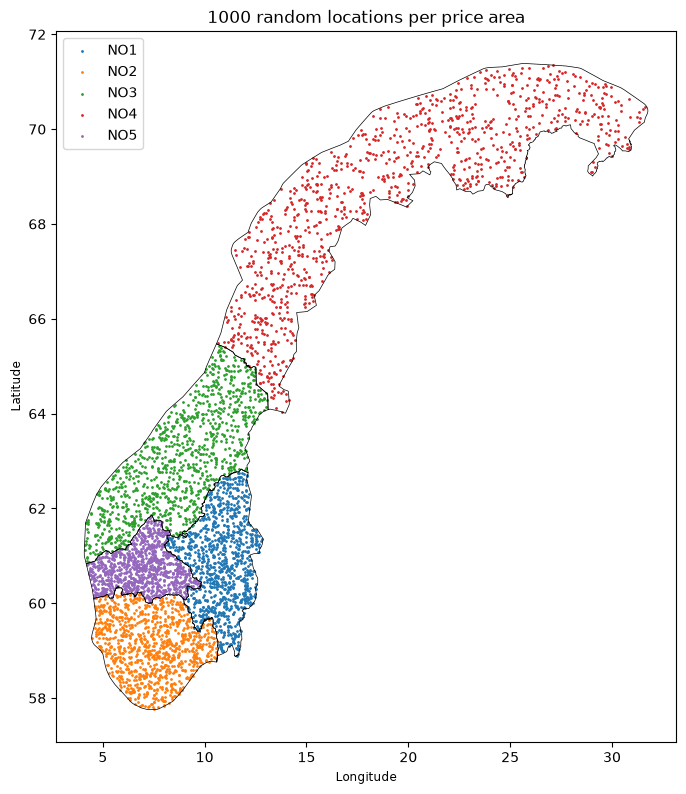

In [9]:
# Price-area boundaries with the sampled points on top
el_outline = all_regions[all_regions["area_type"] == "EL"].to_crs(4326)
el_points = points[points["area_type"] == "EL"]

fig, ax = plt.subplots(figsize=(8, 10))
el_outline.boundary.plot(ax=ax, color="black", linewidth=0.5)
el_points.plot(ax=ax, column="region_id", markersize=1, legend=True)
ax.set_title("1000 random locations per price area")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

### Saving the points

In [10]:
# Saved as CSV, not parquet: *.parquet is in .gitignore, and the
# Streamlit app needs this file in the repository.
POINTS_FILE = Path("../data/sample_points.csv")
points[["region_id", "area_type", "lon", "lat"]].to_csv(POINTS_FILE, index=False)
print("Saved", len(points), "points to", POINTS_FILE)

Saved 9000 points to ..\data\sample_points.csv


## Downloading weather data from open-meteo

Hourly reanalysis data is downloaded from open-meteo's archive API, using the
ERA5 model (`models=era5`; the default "best match" would blend several models).

ERA5 has a grid of about 0.25°, and the API returns the nearest grid cell for
any location. Many of the 1000 sampled points in a region therefore land in the
same cell. The points are snapped to the grid and each cell is downloaded once,
weighted by how many points it stands for, so the regional average is the same
as if all 1000 points had been downloaded one by one.

The free API is limited to 10 000 calls per day and 5 000 per hour, where a
request is weighted as locations × (days / 14) × (variables / 10). The helper
functions below estimate this cost before downloading.

In [11]:
import time
import numpy as np
import requests_cache
from retry_requests import retry

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Variables to download. Precipitation and temperature are required;
# wind and humidity are included as other relevant properties.
WEATHER_VARS = ["temperature_2m", "precipitation",
                "wind_speed_10m", "relative_humidity_2m"]

ERA5_GRID = 0.25   # ERA5 resolution in degrees

# Cached session: a request that has succeeded once is never sent again,
# so re-running the notebook does not use up the API quota.
# retry() resends on "busy" and server errors, waiting longer each time.
cache_session = requests_cache.CachedSession("openmeteo_cache", expire_after=-1)
session = retry(cache_session, retries=5, backoff_factor=2,
                status_to_retry=(429, 500, 502, 503, 504))

# The 1000 sampled points per region from step 5
POINTS = pd.read_csv(POINTS_FILE)

In [12]:
def grid_cells(region_id, points=POINTS, grid=ERA5_GRID):
    """
    Snap a region's sampled points to the ERA5 grid and count how many
    points fall in each cell. The API returns the nearest grid cell anyway,
    so downloading each cell once gives the same result for far fewer calls.
    """
    pts = points[points["region_id"] == region_id]
    snapped = pts.assign(lat=(pts["lat"] / grid).round() * grid,
                         lon=(pts["lon"] / grid).round() * grid)
    return (snapped.groupby(["lat", "lon"]).size()
                   .rename("n_points").reset_index())


def estimate_cost(n_locations, start, end, n_variables):
    """Open-meteo's weighting: locations x (days/14) x (variables/10)."""
    days = (pd.Timestamp(end) - pd.Timestamp(start)).days + 1
    return n_locations * (days / 14) * (n_variables / 10)

In [13]:
def fetch_batch(params, attempts=3):
    """
    Send one request and return (json, from_cache).
    A large reply can be cut off before it is complete. If the JSON can't be
    parsed, the broken copy is deleted from the cache and the request is sent
    again, so a truncated reply is never reused.
    """
    for attempt in range(1, attempts + 1):
        response = session.get(ARCHIVE_URL, params=params, timeout=300)
        response.raise_for_status()
        try:
            return response.json(), response.from_cache
        except ValueError:
            cache_session.cache.delete(requests=[response.request])
            print(f"  incomplete response, retrying ({attempt}/{attempts})")
            time.sleep(30)
    raise RuntimeError("Response still incomplete after several attempts")

### Single location test

One sampled point in NO3 is downloaded first, to see what the API returns.
The returned coordinates differ from the requested ones: the API snaps the
location to the nearest ERA5 grid cell.

In [14]:
# One sampled point in NO3. fetch_batch uses the cached session, so this
# request is only sent once, even if the notebook is re-run.
test_point = POINTS[POINTS["region_id"] == "NO3"].iloc[0]

test_params = {
    "latitude": test_point["lat"],
    "longitude": test_point["lon"],
    "start_date": "2024-01-01",
    "end_date": "2024-12-31",
    "hourly": "temperature_2m,precipitation",
    "models": "era5",      # ERA5 only, not the default blend of models
    "timezone": "UTC",
}

test_json, _ = fetch_batch(test_params)

print("Requested location:", test_point["lat"], test_point["lon"])
print("Returned grid cell:", test_json["latitude"], test_json["longitude"])

test_df = pd.DataFrame(test_json["hourly"])
test_df["time"] = pd.to_datetime(test_df["time"])
print(test_df.shape)
test_df.head()


RetryError: HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=63.2303&longitude=9.5283&start_date=2024-01-01&end_date=2024-12-31&hourly=temperature_2m%2Cprecipitation&models=era5&timezone=UTC (Caused by ResponseError('too many 503 error responses'))

### Download function

`download_weather` takes a region identifier and a time interval, looks up the
region's sampled points, and returns the hourly regional average. With
`n_cells` it downloads a random subset of the region's grid cells instead of
all of them.

In [15]:
def download_weather(region_id, start, end, variables=WEATHER_VARS,
                     n_cells=None, batch_size=10, pause=15, seed=1):
    """
    Download hourly ERA5 data for a region and return the regional average.

    region_id  : e.g. "NO3", "VASS1" - looked up in the sampled points
    start, end : "YYYY-MM-DD"
    variables  : open-meteo hourly variable names
    n_cells    : download a random subset of the region's ERA5 grid cells
                 instead of all of them (None = all). Keeps the API cost down;
                 the regional average changes very little, since the weather
                 varies smoothly across a region.
    batch_size : grid cells per request. Small batches keep each reply small
                 enough to arrive complete.
    pause      : seconds between new requests. 10 cells for a year costs about
                 105 calls, and the limit is 600 per minute, so 15 s is safe.
    seed       : makes the random subset the same on every run
    """
    cells = grid_cells(region_id)
    n_total = len(cells)
    if n_cells is not None and n_cells < n_total:
        # Random rather than head(): grid_cells() is sorted by latitude,
        # so head() would only take the southern part of the region
        cells = cells.sample(n_cells, random_state=seed).reset_index(drop=True)

    cost = estimate_cost(len(cells), start, end, len(variables))
    print(f"{region_id}: {n_total} ERA5 cells in total, downloading {len(cells)} "
          f"(about {cost:.0f} API calls)")

    frames = []
    n_batches = -(-len(cells) // batch_size)   # rounded up
    for i in range(0, len(cells), batch_size):
        batch = cells.iloc[i:i + batch_size]
        params = {
            "latitude": ",".join(batch["lat"].astype(str)),
            "longitude": ",".join(batch["lon"].astype(str)),
            "start_date": start,
            "end_date": end,
            "hourly": ",".join(variables),
            "models": "era5",
            "timezone": "UTC",
        }
        result, from_cache = fetch_batch(params)

        # One location returns an object, several return a list
        if isinstance(result, dict):
            result = [result]

        for location, n in zip(result, batch["n_points"]):
            df = pd.DataFrame(location["hourly"])
            df["weight"] = n        # how many sampled points this cell stands for
            frames.append(df)

        print(f"  batch {i // batch_size + 1}/{n_batches}"
              f"{' (cache)' if from_cache else ''}")
        if not from_cache and i + batch_size < len(cells):
            time.sleep(pause)

    hourly = pd.concat(frames, ignore_index=True)
    hourly["time"] = pd.to_datetime(hourly["time"])

    # Weighted average over the cells for each hour
    weighted = hourly[variables].mul(hourly["weight"], axis=0)
    weighted["weight"] = hourly["weight"]
    weighted["time"] = hourly["time"]
    sums = weighted.groupby("time").sum()
    return sums[variables].div(sums["weight"], axis=0)


In [16]:
# How much deduplication and subsetting save, before any download
cells = grid_cells("NO3")
year = ("2024-01-01", "2024-12-31")
n_vars = len(WEATHER_VARS)

print("Sampled points:   ", cells["n_points"].sum())
print("Unique ERA5 cells:", len(cells))
print()
print("Cost, every point separately:", round(estimate_cost(1000, *year, n_vars)))
print("Cost, every unique cell:     ", round(estimate_cost(len(cells), *year, n_vars)))
print("Cost, 60 random cells:       ", round(estimate_cost(60, *year, n_vars)))


Sampled points:    1000
Unique ERA5 cells: 313

Cost, every point separately: 10457
Cost, every unique cell:      3273
Cost, 60 random cells:        627


### Weather for NO3, 2024

The 1000 points in NO3 map to about 315 ERA5 cells. Downloading all of them
costs more than the free API allows in an hour, and the server repeatedly
returned errors and timeouts when tried. A random subset of 60 cells is
therefore downloaded. Because weather varies smoothly across a region, the
hourly regional average from 60 well-spread cells is very close to the one
from all cells, at a fifth of the cost. The result is saved to a parquet file,
so later runs load it instead of downloading again.

In [ ]:
# Cached to a file, so later runs (and the final Restart + Run All)
# load it instantly instead of downloading again
WEATHER_FILE = Path("weather_NO3_2024.parquet")

if WEATHER_FILE.exists():
    weather = pd.read_parquet(WEATHER_FILE)
    print("Loaded from file")
else:
    weather = download_weather("NO3", "2024-01-01", "2024-12-31", n_cells=60)
    weather.to_parquet(WEATHER_FILE)

print(weather.shape)
weather.head()


NO3: 313 ERA5 cells in total, downloading 60 (about 627 API calls)


RetryError: HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=62.25%2C64.5%2C65.25%2C63.25%2C62.5%2C62.25%2C65.5%2C63.75%2C64.25%2C62.75&longitude=6.25%2C9.25%2C11.5%2C11.5%2C7.5%2C8.75%2C10.75%2C11.5%2C10.5%2C6.5&start_date=2024-01-01&end_date=2024-12-31&hourly=temperature_2m%2Cprecipitation%2Cwind_speed_10m%2Crelative_humidity_2m&models=era5&timezone=UTC (Caused by ResponseError('too many 503 error responses'))

## Precipitation

NameError: name 'weather' is not defined

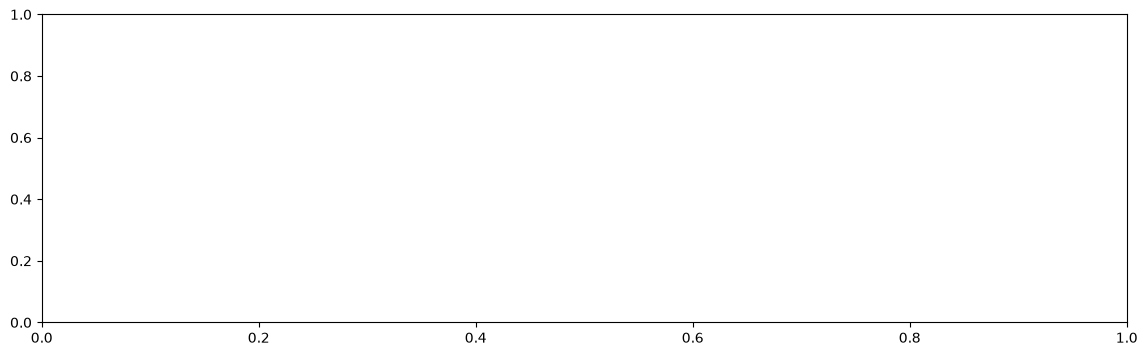

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weather.index, weather["precipitation"], linewidth=0.6)
ax.set_title("Average hourly precipitation, NO3, 2024 (ERA5)")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Precipitation (mm/h)")
ax.grid(alpha=0.3)
plt.show()

### Outliers with DCT and Statistical Process Control

The Discrete Cosine Transform splits the series into cosines of different
speeds. The low coefficients describe slow variation (the seasons and longer
wet or dry periods), the high ones describe fast changes such as single showers.
Setting the low coefficients to zero and transforming back leaves only the fast
part: the seasonally adjusted variations (SATV). This is a high-pass filter.

The SPC boundaries are based on robust statistics of the SATV over the whole
year: the median and the median absolute deviation (MAD, scaled by 1.4826 to be
comparable to a standard deviation). Using these instead of the mean and the
standard deviation means the extreme hours do not widen their own boundaries.

The SATV is not plotted. Instead the boundaries are drawn around the original
series as the slow part ± n robust standard deviations, so they follow the
season. Hours whose SATV lies outside the boundaries are marked as outliers.

The task text calls the result "seasonally adjusted temperature variations" but
applies it to precipitation. The instruction is followed (precipitation), and
the name SATV is kept.

In [ ]:
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation

def spc_outliers(series, cutoff_days=30, n_sigma=3.0, title="Precipitation"):
    """
    Statistical Process Control on a high-pass filtered series.

    series      : hourly pandas Series with a time index
    cutoff_days : DCT frequency cut-off, given as a period in days.
                  Variation slower than this is removed (the seasonal part).
    n_sigma     : number of robust standard deviations to the boundaries

    Returns (figure, summary dict, DataFrame of the outliers).
    """
    x = series.to_numpy(dtype=float)
    n = len(x)

    # DCT coefficient k is a cosine with period 2n/k samples (hours here),
    # so the cut-off period in days gives the cut-off index like this:
    k_cut = int(round(2 * n / (cutoff_days * 24)))

    coeffs = dct(x, type=2, norm="ortho")
    low = coeffs.copy()
    low[k_cut:] = 0                              # keep only the slow coefficients
    seasonal = idct(low, type=2, norm="ortho")   # slow part, back in time domain
    satv = x - seasonal                          # high-pass: the fast variations

    # Robust statistics over the whole year: median and MAD instead of
    # mean and std, so the extreme hours don't widen their own threshold.
    # scale="normal" multiplies MAD by 1.4826 to make it comparable to a std.
    centre = np.median(satv)
    sigma = median_abs_deviation(satv, scale="normal")

    upper = seasonal + centre + n_sigma * sigma
    lower = seasonal + centre - n_sigma * sigma
    is_out = np.abs(satv - centre) > n_sigma * sigma

    # Plot the original series with the boundaries. SATV itself is not plotted.
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(series.index, x, color="steelblue", linewidth=0.6, label=title)
    ax.plot(series.index, upper, color="black", linestyle="--", linewidth=1,
            label=f"SPC boundaries (±{n_sigma} robust σ)")
    ax.plot(series.index, lower, color="black", linestyle="--", linewidth=1)
    ax.scatter(series.index[is_out], x[is_out], color="crimson", s=10,
               zorder=3, label="Outliers")
    ax.set_title(f"{title}: SPC outliers (DCT cut-off {cutoff_days} days)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

    outliers = pd.DataFrame({"value": x[is_out], "satv": satv[is_out]},
                            index=series.index[is_out])
    summary = {
        "n_hours": n,
        "n_outliers": int(is_out.sum()),
        "share_outliers_pct": round(float(100 * is_out.mean()), 2),
        "cutoff_days": cutoff_days,
        "dct_cutoff_index": k_cut,
        "n_sigma": n_sigma,
        "robust_sigma": round(float(sigma), 4),
    }
    return fig, summary, outliers

In [ ]:
# Default parameters
fig, summary, outliers = spc_outliers(weather["precipitation"],
                                      title="Precipitation (mm/h)")
plt.show()
print(summary)
outliers.sort_values("value", ascending=False).head(10)

NameError: name 'weather' is not defined

In [ ]:
# Stricter boundaries and a shorter cut-off, to show the parameters in use
fig, summary, outliers = spc_outliers(weather["precipitation"], cutoff_days=7,
                                      n_sigma=5, title="Precipitation (mm/h)")
plt.show()
print(summary)

NameError: name 'weather' is not defined

Precipitation is very skewed: most hours have little or no rain, and a few have
a lot. The outliers are therefore almost all on the upper side, and the share of
outliers is higher than it would be for a symmetric variable such as
temperature. A shorter cut-off removes more of the slow variation, so the
boundaries follow the series more closely, and a higher number of standard
deviations keeps only the most extreme hours.

## Temperature

### Anomalies with Local Outlier Factor

Local Outlier Factor compares the density around each point with the density
around its nearest neighbours. A point in a much sparser area than its
neighbours is an anomaly. The features are the position in time and the
temperature, scaled to the same range so neither dominates. This way a point is
compared with the hours around it, so a cold hour in winter is not an anomaly,
but a sudden jump away from the surrounding hours is.

The proportion of outliers (`contamination`) defaults to 1 %, as the task asks.

In [ ]:
# Average hourly temperature over the downloaded grid cells
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weather.index, weather["temperature_2m"], linewidth=0.6)
ax.set_title("Average hourly temperature, NO3, 2024 (ERA5)")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.3)
plt.show()

In [ ]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

def lof_anomalies(series, contamination=0.01, n_neighbors=20,
                  title="Temperature (°C)"):
    """
    Anomaly detection with Local Outlier Factor.

    series        : hourly pandas Series with a time index
    contamination : expected proportion of anomalies (default 1 %)
    n_neighbors   : number of neighbours each point is compared with

    Returns (figure, summary dict, DataFrame of the anomalies).
    """
    values = series.to_numpy(dtype=float)

    # Features: position in time and value, scaled to the same range
    X = StandardScaler().fit_transform(
        np.column_stack([np.arange(len(values)), values]))

    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_out = lof.fit_predict(X) == -1          # -1 marks an anomaly

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(series.index, values, color="steelblue", linewidth=0.6, label=title)
    ax.scatter(series.index[is_out], values[is_out], color="crimson", s=10,
               zorder=3, label="Anomalies (LOF)")
    ax.set_title(f"{title}: Local Outlier Factor anomalies "
                 f"(contamination {contamination:.0%})")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

    anomalies = pd.DataFrame({"value": values[is_out]},
                             index=series.index[is_out])
    summary = {
        "n_hours": len(values),
        "n_anomalies": int(is_out.sum()),
        "share_anomalies_pct": round(float(100 * is_out.mean()), 2),
        "contamination": contamination,
        "n_neighbors": n_neighbors,
        "min_anomaly": round(float(values[is_out].min()), 2),
        "max_anomaly": round(float(values[is_out].max()), 2),
    }
    return fig, summary, anomalies

In [ ]:
# Default parameters: 1 % anomalies
fig, summary, anomalies = lof_anomalies(weather["temperature_2m"])
plt.show()
print(summary)
anomalies.head(10)

In [ ]:
# More anomalies and a wider neighbourhood, to show the parameters in use
fig, summary, anomalies = lof_anomalies(weather["temperature_2m"],
                                        contamination=0.03, n_neighbors=50)
plt.show()
print(summary)

## Reservoir filling: STL decomposition

Seasonal-Trend decomposition using LOESS (STL) splits a series into a trend, a
seasonal pattern and a residual. It is applied to the weekly filling level from
the Magasinstatistikk API for NO3, the same area as the weather data.

The data is weekly, so the period is 52. The seasonal and trend smoothers are
window lengths and must be odd; the trend window must be longer than the
period. With `robust=True`, single unusual weeks get less weight, so they do
not distort the trend and the seasonal pattern.

In [ ]:
import sys
sys.path.insert(0, "../modules")      # lets the notebook import our own modules
from nve_api import fetch_reservoirs, select_area

# Weekly filling level for NO3 from the Magasinstatistikk API
reservoirs = fetch_reservoirs()
fill = select_area(reservoirs, area_type="EL", area_number=3)["filling_level"]

print("Weeks:", len(fill), " from", fill.index.min().date(), "to", fill.index.max().date())
fill.tail()

In [ ]:
from statsmodels.tsa.seasonal import STL

def stl_decomposition(series, period=52, seasonal=13, trend=89, robust=True,
                      title="Filling level, NO3"):
    """
    STL decomposition of a weekly series.

    period   : length of the seasonal cycle in observations (52 weeks)
    seasonal : seasonal smoother window, odd number
    trend    : trend smoother window, odd number larger than period
    robust   : down-weight unusual observations

    Returns the figure.
    """
    # Regular weekly index (the data is published on Sundays); interpolate
    # any missing weeks, since STL needs evenly spaced observations
    s = series.asfreq("W-SUN").interpolate()

    result = STL(s, period=period, seasonal=seasonal, trend=trend,
                 robust=robust).fit()

    fig = result.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle(f"{title}: STL (seasonal={seasonal}, trend={trend}, "
                 f"robust={robust})", y=1.02)
    fig.tight_layout()
    return fig

In [ ]:
# Default parameters
fig = stl_decomposition(fill)
plt.show()

In [ ]:
# Shorter smoothers and no robust fitting, to show the parameters in use
fig = stl_decomposition(fill, seasonal=7, trend=61, robust=False)
plt.show()

The trend shows how the general filling level drifts over the years, the
seasonal component the yearly cycle of filling during snowmelt and emptying in
winter, and the residual what is left. A shorter seasonal smoother lets the
seasonal pattern change more from year to year, and without robust fitting
single unusual weeks pull the trend and seasonal parts more.

## Spectrogram

The spectrogram shows how the strength of different frequencies in the filling
level changes over time. The series is cut into overlapping windows, and the
frequency content of each window is computed. With weekly data and a sampling
frequency of 52 per year, the frequency axis is in cycles per year, so the
yearly cycle appears as a band at 1.

The window length and overlap are in weeks. A longer window gives sharper
frequencies but less detail in time.

In [ ]:
from scipy.signal import spectrogram

def spectrogram_plot(series, window_length=104, overlap=78,
                     title="Filling level, NO3"):
    """
    Spectrogram of a weekly series.

    window_length : weeks per window (default two years)
    overlap       : weeks shared by neighbouring windows, less than window_length

    Returns the figure.
    """
    if overlap >= window_length:
        raise ValueError("overlap must be smaller than window_length")

    s = series.asfreq("W-SUN").interpolate()

    # fs=52 samples per year, so frequencies come out in cycles per year;
    # detrend removes the slow drift inside each window
    freqs, t, power = spectrogram(s.to_numpy(), fs=52, nperseg=window_length,
                                  noverlap=overlap, detrend="linear")

    # t is in years from the start; convert to dates for the x-axis
    times = s.index[0] + pd.to_timedelta(t * 365.25, unit="D")

    fig, ax = plt.subplots(figsize=(12, 5))
    mesh = ax.pcolormesh(times, freqs, 10 * np.log10(power + 1e-12),
                         shading="auto")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set_title(f"{title}: spectrogram (window {window_length} weeks, "
                 f"overlap {overlap})")
    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency (cycles per year)")
    return fig

In [ ]:
# Default parameters: two-year windows
fig = spectrogram_plot(fill)
plt.show()

In [ ]:
# Three-year windows: sharper frequencies, less detail in time
fig = spectrogram_plot(fill, window_length=156, overlap=130)
plt.show()

## Log

Part 3 added weather data and time-series analysis to the project. Once the data
was in place the analysis was fairly quick to write; getting the data was the
hard part.

The first task was finding the shapefiles. In NVE's atlas the price areas are
not called elspot areas but budområder, under Nettanlegg and Nettområder, which
took a while to find. The region file has five NVE regions, while the
Magasinstatistikk uses three watercourse areas, so I merged Sør and Øst into one
area and Midt and Nord into another with dissolve. I also added Norway as a
whole, as the union of the price areas, so every area type in the app has a
region. The 1000 points per region were sampled while still in UTM coordinates,
so they are spread evenly by area, and converted to longitude and latitude
afterwards.

The weather download caused most of the problems. The open-meteo API is free,
but each request is weighted by locations, days and variables, and 1000
locations for a full year would use more than the whole daily quota. Since ERA5
has a 0.25° grid and the API returns the nearest grid cell anyway, I snapped the
points to the grid and downloaded each cell once, weighted by how many points it
stands for. For NO3 this turned 1000 points into 313 cells. The server still
returned errors and timeouts, and one large reply arrived cut off and was stored
in the cache, so I made the batches smaller and delete broken replies before
retrying. After comparing approaches with a classmate I download a random subset
of 60 cells, and save the result to a file.

For precipitation, a DCT high-pass filter removes the slow seasonal part, and
the SPC boundaries come from the median and MAD of what is left. For temperature
I used Local Outlier Factor on time and temperature together. STL and the
spectrogram use the weekly filling level for NO3.

[Streamlit: add a few sentences here when the app is updated.]

## Use of AI

I used Claude (Anthropic) throughout Part 3. It helped me find the right
shapefiles, understand the open-meteo quota and design the download around it,
and work through the errors from the API. It also explained the methods (DCT
filtering, robust statistics, Local Outlier Factor, STL and the spectrogram)
and drafted parts of the code and the explanations in this notebook. I ran all
the code, checked the results and adjusted it where needed, and I made the
choices about the regions, the grid-cell download and the parameters myself.